# 55 — Per-pocket Δscore vs Δrank (and Δscore → ΔEF), every condition vs the default

Companion to nb52. nb52 compares conditions by their **population** curves (EF ladder, score survival, rank ECDF). Here every condition is compared **pocket by pocket** against the default, `CCD + Bound pocket` (`source_ccd`: crystal pocket, CCD library, idealised-CCD ground truth).

For each condition, a pocket enters the comparison only if it is `valid & in_library` in **both** the default and that condition (paired on `pocket_id, dataset`). Then

* **Δscore** = `gt_score(cond) – gt_score(default)` — change in ensemble cosine score of the true ligand.
* **Δlog₁₀rank** = `log10 gt_rank(cond) – log10 gt_rank(default)` — **positive = worse**. Log, because a raw Δrank is dominated by the tail (rank 1→20 and 20,000→20,019 are not the same event).

### Why Δscore and Δrank aren't the same thing
Rank is the true ligand's score *relative to that pocket's own 49k-molecule background*. If a condition shifts every molecule's score for a pocket by the same amount (a calibration shift), Δscore is large but Δrank ≈ 0. Points far off the main trend — especially the "score ↓ but rank ↑" and "score ↑ but rank ↓" quadrants — are where the pocket embedding has moved *globally* rather than lost or gained specificity for this ligand.

### Built-in floor
A pocket already at rank 1 in the default can only stay or get worse. The hexbins are coloured by **default rank** precisely so that this floor (dark cells pinned at Δlog₁₀rank ≥ 0) is visible rather than read as a real effect.

### Linking to EF (which is not a pocket-level number)
EF@1% is a population statistic, but its atomic unit is per-pocket: `hit = gt_rank ≤ 1% of N_CCD (490)`. Pooled EF over **any subset** of pockets is `Σhit / Σ(pct_k/n_lib)`, so we can compute a *local* EF inside each Δscore bin, for the condition and for the default on the very same pockets. That gives:

1. **Bridge plot** — matched ΔEF@1% per Δscore bin, plus the hit-loss rate `P(miss in cond | hit in default)`. If curves from different conditions collapse onto each other, Δscore is a sufficient summary of how much EF a condition will cost; if they don't, conditions with the same Δscore degrade EF differently (i.e. via background/calibration shifts).
2. **Condition-level trajectories** — one point per (condition, de-leak level): median Δscore vs matched ΔEF@1%, joined across the nb52 ladder.

**Matched ΔEF ≠ nb52's EF gap**: the default's EF here is recomputed on the condition's own valid subset (e.g. the 6.9k pockets that have an apo structure), so selection effects cancel.

In [1]:
from __future__ import annotations

import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm, ListedColormap
from matplotlib.ticker import ScalarFormatter
from scipy.stats import spearmanr, pearsonr
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.DataStructs import BulkTanimotoSimilarity
RDLogger.DisableLog('rdApp.*')

PROJ    = Path.cwd().parent / 'DATA' / 'drugclip'
BENCH   = PROJ / 'RESULTS' / 'benchmark'
NL_ROOT = Path.cwd().parent / 'DATA' / 'natural_ligands'
sys.path.insert(0, str(Path.cwd() / 'natural_ligands_scripts'))
from ligand_frequency_analysis import train_ligand_freq

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.labelsize': 12, 'xtick.labelsize': 8,
                     'ytick.labelsize': 8})

ds_order = ['coach420', 'scpdb', 'holo4k', 'pdbbind2020']
DATASET_PRIORITY = ['coach420', 'scpdb', 'pdbbind2020', 'holo4k']  # nb49 order
N_CCD = 48_999   # CCD library size (nb52)
PCT_K = max(1, round(0.01 * N_CCD))

# --- figure text conventions: en dash as minus, thousands comma only from 5 digits ---
DASH = '–'


def fmt_n(n: int) -> str:
    return f'{n:,}' if abs(n) >= 10_000 else str(n)


def fmt_num(x: float, spec: str) -> str:
    return format(x, spec).replace('-', DASH)


class DashFormatter(ScalarFormatter):
    def __call__(self, x, pos=None):
        return super().__call__(x, pos).replace('−', DASH).replace('-', DASH)


def dash_ticks(fig):
    # swap every numeric tick formatter (incl. colorbars) for the en-dash one
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if type(axis.get_major_formatter()) is ScalarFormatter:
                axis.set_major_formatter(DashFormatter())

# nb52 registry, unchanged colours/labels
CONDITIONS = [
    ('bound_bound',               '#2CA02C', 'Bound + Bound pocket'),
    ('source_ccd',                '#17BECF', 'CCD + Bound pocket'),
    ('holo_ccd',                  '#FF7F0E', 'CCD + Holo pocket'),
    ('apo_ccd',                   '#1F77B4', 'CCD + Apo pocket'),
    ('afdb_translated_ccd',       '#9467BD', 'CCD + AFDB-translated'),
    ('afdb_p2rank_correct_ccd',   '#D62728', 'CCD + AFDB P2Rank ✓'),
    ('pdb_p2rank_correct_ccd',    '#E377C2', 'CCD + PDB P2Rank ✓'),
    ('afdb_p2rank_wrong_ccd',     '#7F7F7F', 'CCD + AFDB P2Rank ✗'),
    ('pdb_p2rank_wrong_ccd',      '#8C564B', 'CCD + PDB P2Rank ✗'),
    ('patches_ccd',               '#000000', 'CCD + Patches'),
]
COND_IDS    = [c[0] for c in CONDITIONS]
COND_COLOUR = {c[0]: c[1] for c in CONDITIONS}
COND_LABEL  = {c[0]: c[2] for c in CONDITIONS}
DEFAULT     = 'source_ccd'
CMP_CONDS   = [c for c in COND_IDS if c != DEFAULT]

## Load all 10 conditions from the nb43/nb52 caches + cross-dataset dedup (identical to nb52)

In [2]:
def dedup_cross_dataset(pp: pd.DataFrame,
                        priority: list[str] = DATASET_PRIORITY) -> pd.DataFrame:
    key = pd.Series(list(zip(pp['pdb_id'].str.lower().str.strip(),
                              pp['lig_resname'].str.upper())), index=pp.index)
    winner = pp.groupby(key)['dataset'].transform(
        lambda s: next(d for d in priority if d in set(s)))
    return pp[pp['dataset'] == winner].copy()


pooled: dict[str, pd.DataFrame] = {}
for cond in COND_IDS:
    df = pd.concat([pd.read_parquet(BENCH / f'{ds}_{cond}_screen.parquet') for ds in ds_order],
                   ignore_index=True)
    df = dedup_cross_dataset(df)
    n_zero = int((pd.to_numeric(df['gt_rank'], errors='coerce') < 1).sum())
    if n_zero:
        # nb52 bound_bound cache has 1 pocket (pdbbind2020_2vuk_P83_A_1) at gt_rank=0,
        # an off-by-one in its own-CCD-row exclusion; ranks are >= 1 by definition
        print(f'  [{cond}] clipping {n_zero} gt_rank < 1 to 1')
        df['gt_rank'] = pd.to_numeric(df['gt_rank'], errors='coerce').clip(lower=1)
    df['ok'] = (df['valid'].fillna(False).astype(bool)
                & df['in_library'].fillna(False).astype(bool)
                & df['gt_rank'].notna() & df['gt_score'].notna())
    pooled[cond] = df
    print(f'{COND_LABEL[cond]:24s} deduped n={len(df):,}  valid&in_library n={int(df["ok"].sum()):,}')

  [bound_bound] clipping 1 gt_rank < 1 to 1
Bound + Bound pocket     deduped n=15,640  valid&in_library n=15,640


CCD + Bound pocket       deduped n=15,640  valid&in_library n=15,533


CCD + Holo pocket        deduped n=15,640  valid&in_library n=10,718


CCD + Apo pocket         deduped n=15,640  valid&in_library n=6,867


CCD + AFDB-translated    deduped n=15,640  valid&in_library n=12,930


CCD + AFDB P2Rank ✓      deduped n=15,640  valid&in_library n=8,233


CCD + PDB P2Rank ✓       deduped n=15,640  valid&in_library n=13,327


CCD + AFDB P2Rank ✗      deduped n=15,640  valid&in_library n=8,299


CCD + PDB P2Rank ✗       deduped n=15,640  valid&in_library n=14,542


CCD + Patches            deduped n=15,640  valid&in_library n=15,533


## De-leakage level masks (copied verbatim from nb52)

In [3]:
TRAIN_JSON   = NL_ROOT / 'DATA' / 'DRUGCLIP_BIOLIP_TRAINING.json'
SEQ_ID_TSV   = NL_ROOT / 'RESULTS' / 'deleakage' / 'pocket_seq_identity.tsv'
CCD_MANIFEST = NL_ROOT / 'RESULTS' / 'components_pub_unimol_manifest.tsv'

folds = json.loads(TRAIN_JSON.read_text())
training_union: set[str] = {x.lower().strip() for v in folds.values() for x in v}
seq_df = pd.read_csv(SEQ_ID_TSV, sep='\t')
pocket_best_pident = dict(zip(seq_df['pocket'], seq_df['best_pident']))
LIG_FREQ = train_ligand_freq().set_index('ligand')['n_pdbs'].to_dict()

eval_codes: set[str] = set()
for df in pooled.values():
    eval_codes |= set(df.loc[df['ok'], 'lig_resname'].str.upper().dropna())
train_codes = {c.upper() for c in LIG_FREQ}
man = pd.read_csv(CCD_MANIFEST, sep='\t', dtype=str)
man = man[man['identifier'].str.upper().isin(eval_codes | train_codes)]
fp_map: dict[str, object] = {}
for code_, smi in zip(man['identifier'], man['smiles']):
    if isinstance(smi, str) and smi:
        m = Chem.MolFromSmiles(smi)
        if m is not None:
            fp_map[str(code_).upper()] = AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048)
train_fps = [fp_map[c] for c in train_codes if c in fp_map]
NN_TS: dict[str, float] = {}
for c in eval_codes:
    if c in fp_map:
        sims = BulkTanimotoSimilarity(fp_map[c], train_fps)
        NN_TS[c] = max(sims) if sims else 0.0

DE_LEVELS = ['L0', 'L1', 'L2<0.7', 'L2<0.5', 'L2<0.3',
             'L3<100', 'L3<25', 'L3<5', 'L3=0',
             'L4<0.9', 'L4<0.7', 'L4<0.5', 'L4<0.3']


def format_level_label(level: str) -> str:
    m = re.match(r'L(\d)(<|=)?(.*)', level)
    stage, op, rest = m.group(1), m.group(2), m.group(3)
    label = f'L$_{{{stage}}}$'
    if op:
        label += f' {op} {rest}'
    return label


DE_LEVELS_FMT = [format_level_label(lv) for lv in DE_LEVELS]


def get_level_mask(df: pd.DataFrame, level: str) -> np.ndarray:
    mask = np.ones(len(df), dtype=bool)
    if level == 'L0':
        return mask
    mask &= ~df['pdb_id'].str.lower().str.strip().isin(training_union).to_numpy()
    if level == 'L1':
        return mask
    bid = df['pocket_id'].map(pocket_best_pident).fillna(0.0).to_numpy()
    if level.startswith('L2<'):
        return mask & (bid < float(level.split('<')[1]))
    mask &= (bid < 0.3)
    lig_freq = df['lig_resname'].str.upper().map(LIG_FREQ).fillna(0).astype(int).to_numpy()
    if level.startswith('L3<'):
        return mask & (lig_freq < float(level.split('<')[1]))
    mask &= (lig_freq == 0)
    if level == 'L3=0':
        return mask
    nn_ts = df['lig_resname'].str.upper().map(NN_TS).fillna(1.0).to_numpy()
    return mask & (nn_ts < float(level.split('<')[1]))


PLOT_LEVEL = 'L3<25'   # nb52's choice for single-level plots

## Paired frames

One row per pocket valid in both the default and the condition. The de-leak mask is evaluated on the default's rows (it only depends on pocket/ligand identity, so it's the same mask in every condition).

In [4]:
KEY = ['pocket_id', 'dataset']


def paired(cond: str, level: str = 'L0') -> pd.DataFrame:
    d = pooled[DEFAULT]
    d = d[d['ok'] & get_level_mask(d, level)]
    c = pooled[cond]
    c = c[c['ok']]
    m = (d[KEY + ['pdb_id', 'lig_resname', 'gt_score', 'gt_rank']]
         .merge(c[KEY + ['gt_score', 'gt_rank']], on=KEY, suffixes=('_def', '_cond')))
    m['d_score']   = m['gt_score_cond'] - m['gt_score_def']
    m['log_r_def'] = np.log10(m['gt_rank_def'].astype(float))
    m['d_logrank'] = np.log10(m['gt_rank_cond'].astype(float)) - m['log_r_def']
    m['hit_def']   = m['gt_rank_def']  <= PCT_K
    m['hit_cond']  = m['gt_rank_cond'] <= PCT_K
    return m


def ef(hits: pd.Series) -> float:
    # pooled EF@1% = Σhit / Σ(pct_k / n_lib); n_lib constant -> hit rate × N/pct_k
    return hits.mean() * N_CCD / PCT_K if len(hits) else np.nan


def summarise(m: pd.DataFrame, rng=None, n_boot: int = 1000) -> dict:
    rho = spearmanr(m['d_score'], m['d_logrank']).statistic if len(m) > 2 else np.nan
    r   = pearsonr(m['d_score'], m['d_logrank']).statistic if len(m) > 2 else np.nan
    ef_d, ef_c = ef(m['hit_def']), ef(m['hit_cond'])
    out = {'n': len(m),
           'median Δscore': m['d_score'].median(),
           'median Δlog10rank': m['d_logrank'].median(),
           'Spearman ρ': rho, 'Pearson r': r,
           # off-diagonal quadrants: score and rank move "the wrong way" together
           '% score↓ rank↑': 100 * ((m['d_score'] < 0) & (m['d_logrank'] < 0)).mean(),
           '% score↑ rank↓': 100 * ((m['d_score'] > 0) & (m['d_logrank'] > 0)).mean(),
           '% hits lost': 100 * (m['hit_def'] & ~m['hit_cond']).sum() / max(1, m['hit_def'].sum()),
           '% misses gained': 100 * (~m['hit_def'] & m['hit_cond']).sum() / max(1, (~m['hit_def']).sum()),
           'EF default (matched)': ef_d, 'EF cond': ef_c, 'ΔEF': ef_c - ef_d}
    if rng is not None and len(m) > 10:
        hd, hc = m['hit_def'].to_numpy(), m['hit_cond'].to_numpy()
        idx = rng.integers(0, len(m), size=(n_boot, len(m)))
        boots = (hc[idx].mean(1) - hd[idx].mean(1)) * N_CCD / PCT_K
        out['ΔEF 95% CI'] = f'[{np.percentile(boots, 2.5):.1f}, {np.percentile(boots, 97.5):.1f}]'
    return out


rng = np.random.default_rng(0)
summary = {}
for level in ['L0', PLOT_LEVEL]:
    rows = {COND_LABEL[c]: summarise(paired(c, level), rng) for c in CMP_CONDS}
    summary[level] = pd.DataFrame(rows).T
    print(f'\n—— paired vs {COND_LABEL[DEFAULT]}  @ {level} ——')
    display(summary[level].round(2))


—— paired vs CCD + Bound pocket  @ L0 ——


,n,median Δscore,median Δlog10rank,Spearman ρ,Pearson r,% score↓ rank↑,% score↑ rank↓,% hits lost,% misses gained,EF default (matched),EF cond,ΔEF,ΔEF 95% CI
Bound + Bound pocket,15533,-0.001717,0.0,-0.909701,-0.839173,0.0,0.0,1.91373,10.951374,84.772621,84.817686,0.045064,"[-0.3, 0.3]"
CCD + Holo pocket,10718,-0.064395,0.170883,-0.792543,-0.887815,12.922187,1.754059,14.07847,8.956146,84.892837,74.294061,-10.598776,"[-11.2, -10.0]"
CCD + Apo pocket,6867,-0.171862,0.740363,-0.88174,-0.899114,8.140382,1.004806,30.89172,8.54606,86.877505,61.160831,-25.716673,"[-26.8, -24.7]"
CCD + AFDB-translated,12930,-0.087388,0.46505,-0.902488,-0.924882,7.208043,2.443929,28.151415,8.26002,84.174616,61.785282,-22.389334,"[-23.1, -21.7]"
CCD + AFDB P2Rank ✓,8233,-0.509683,2.431329,-0.900448,-0.904728,1.42111,0.364387,80.66031,2.155887,85.349892,16.8222,-68.527692,"[-69.5, -67.5]"
CCD + PDB P2Rank ✓,13327,-0.415129,2.029384,-0.904027,-0.904132,1.838373,0.742853,69.559574,5.141243,86.716922,27.079811,-59.637111,"[-60.5, -58.8]"
CCD + AFDB P2Rank ✗,8299,-0.696997,3.062115,-0.860009,-0.913819,1.662851,0.168695,97.410676,3.246753,83.297493,2.699065,-80.598427,"[-81.5, -79.8]"
CCD + PDB P2Rank ✗,14542,-0.693685,2.978761,-0.86903,-0.913503,2.076743,0.089396,96.6759,3.791887,84.402073,3.396987,-81.005086,"[-81.7, -80.4]"
CCD + Patches,15533,-0.689555,3.147529,-0.865365,-0.919284,1.178137,0.070817,99.248177,1.099366,84.772621,0.804722,-83.967899,"[-84.6, -83.4]"



—— paired vs CCD + Bound pocket  @ L3<25 ——


,n,median Δscore,median Δlog10rank,Spearman ρ,Pearson r,% score↓ rank↑,% score↑ rank↓,% hits lost,% misses gained,EF default (matched),EF cond,ΔEF,ΔEF 95% CI
Bound + Bound pocket,537,0.00014,0.0,-0.950977,-0.888692,0.0,0.0,3.458213,7.894737,64.616931,65.175579,0.558648,"[-1.3, 2.4]"
CCD + Holo pocket,336,-0.047655,0.107666,-0.860386,-0.917707,12.202381,1.488095,25.352113,7.317073,63.391563,49.99898,-13.392584,"[-17.9, -9.2]"
CCD + Apo pocket,111,-0.091394,0.342606,-0.942041,-0.935491,5.405405,4.504505,49.253731,4.545455,60.359129,32.431771,-27.927358,"[-36.9, -18.9]"
CCD + AFDB-translated,437,-0.082811,0.307681,-0.917734,-0.940146,7.093822,2.974828,38.709677,12.025316,63.843091,43.477374,-20.365717,"[-25.2, -15.3]"
CCD + AFDB P2Rank ✓,258,-0.284168,1.072796,-0.931496,-0.927977,2.325581,1.162791,82.5,5.102041,62.014238,12.790437,-49.223802,"[-55.8, -42.2]"
CCD + PDB P2Rank ✓,451,-0.323917,1.401561,-0.925575,-0.919808,0.886918,0.886918,84.175084,4.545455,65.852315,11.973148,-53.879166,"[-58.8, -49.2]"
CCD + AFDB P2Rank ✗,267,-0.48582,1.615653,-0.931932,-0.916313,2.247191,0.0,96.319018,3.846154,61.047443,3.745242,-57.302201,"[-63.7, -50.6]"
CCD + PDB P2Rank ✗,524,-0.502758,1.779473,-0.934094,-0.922493,5.534351,0.19084,96.153846,5.376344,64.5025,4.389223,-60.113277,"[-64.5, -55.9]"
CCD + Patches,537,-0.472962,1.813733,-0.941906,-0.932808,2.607076,0.18622,97.40634,2.631579,64.616931,2.607023,-62.009908,"[-66.1, -57.9]"


## Plot 1 — Δscore vs Δlog₁₀rank, hexbin per condition, coloured by default rank

Each hex is coloured by the **median log₁₀(default rank)** of the pockets inside it (dark = default already near rank 1). Dashed lines at 0. Lower-left → upper-right is impossible-ish (score up, rank worse) unless the background moved more than the ligand; the main mass should run upper-left → lower-right (score down ⇒ rank worse).

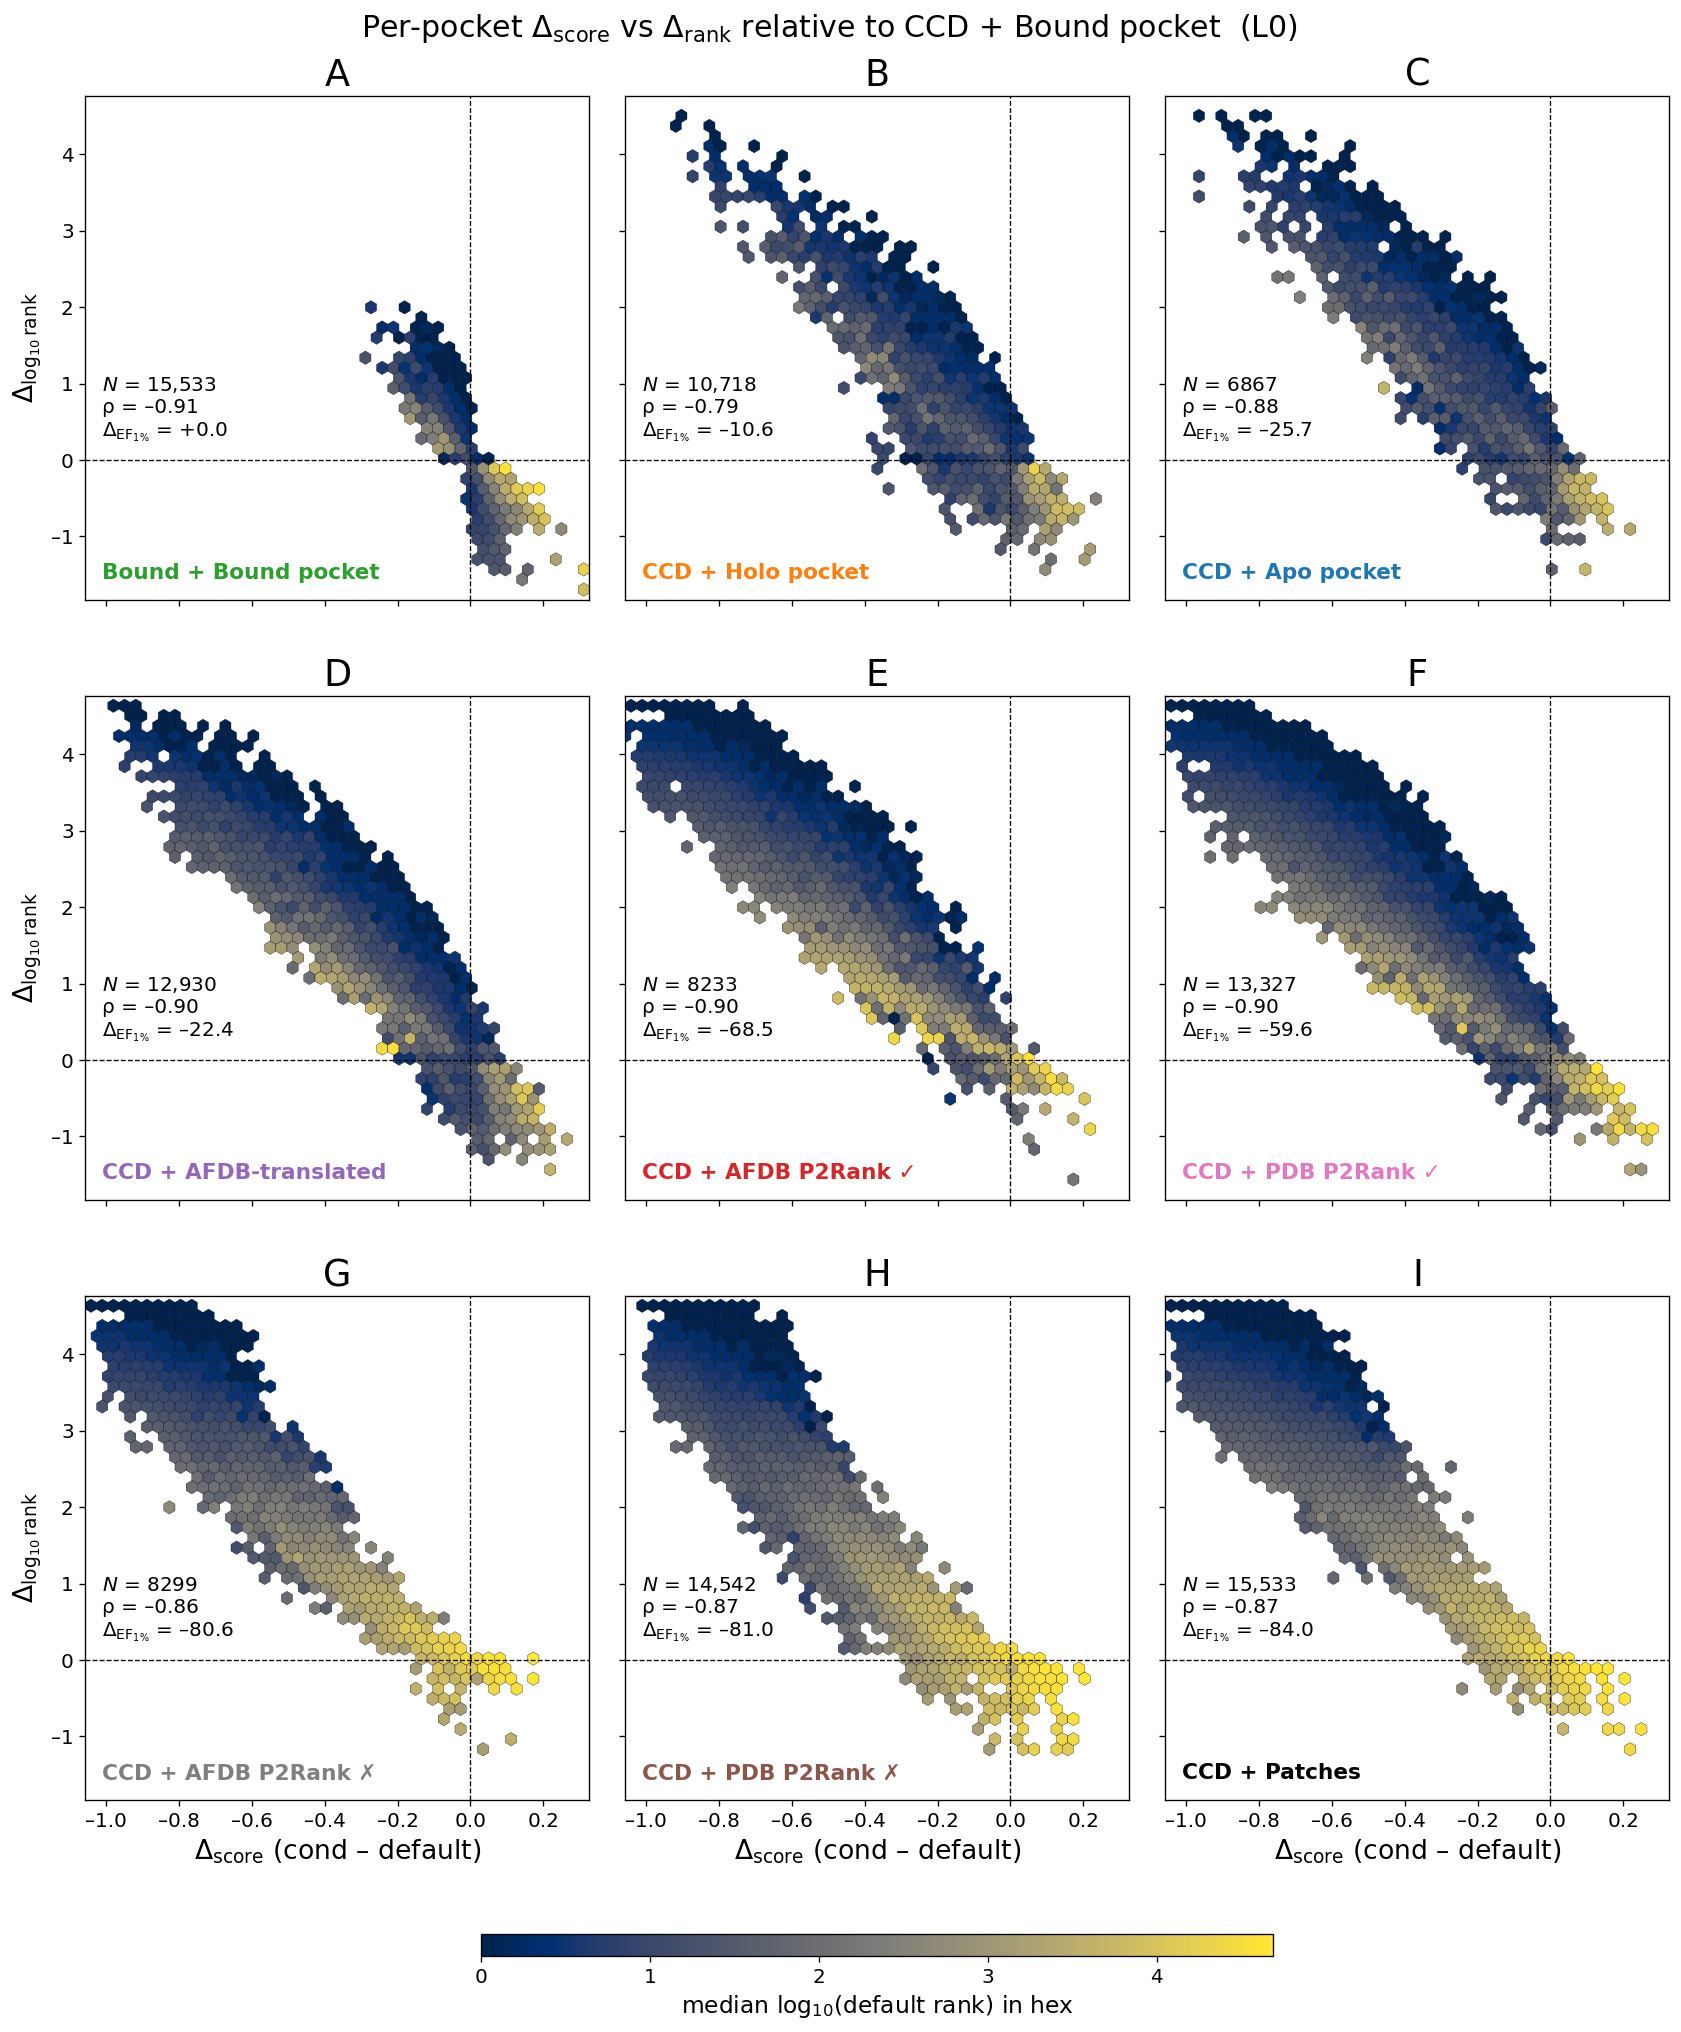

In [5]:
RANK_NORM = Normalize(0, np.log10(N_CCD))
RANK_CMAP = plt.colormaps.get_cmap('cividis')
# count mode: single-hue sequential, light -> dark; lightest 15% dropped so 1-pocket hexes stay visible
COUNT_CMAP = ListedColormap(plt.colormaps.get_cmap('Blues')(np.linspace(0.15, 1, 256)))


def hex_panels(level: str, gridsize: int, mincnt: int, fname: str, colour_by: str = 'rank'):
    # colour_by: 'rank' = median log10(default rank) per hex; 'count' = pockets per hex (log scale)
    pairs = {c: paired(c, level) for c in CMP_CONDS}
    xs = np.concatenate([p['d_score'] for p in pairs.values()])
    ys = np.concatenate([p['d_logrank'] for p in pairs.values()])
    xlim = (np.nanpercentile(xs, 0.2) - 0.02, np.nanpercentile(xs, 99.8) + 0.02)
    ylim = (np.nanpercentile(ys, 0.2) - 0.1,  np.nanpercentile(ys, 99.8) + 0.1)

    # explicit layout (inches) so square panels fill the figure with tight column gaps
    P, CG, RG = 4.2, 0.3, 0.8               # panel side, column gap, row gap
    L, R, T, B = 1.0, 0.2, 1.0, 2.0         # margins: y-label | right | suptitle | x-label + colourbar
    W, H = L + 3 * P + 2 * CG + R, T + 3 * P + 2 * RG + B
    fig, axes = plt.subplots(3, 3, figsize=(W, H), sharex=True, sharey=True)
    fig.subplots_adjust(left=L / W, right=1 - R / W, bottom=B / H, top=1 - T / H,
                        wspace=CG / P, hspace=RG / P)
    FS_LABEL, FS_TICK, FS_TEXT = 16, 12, 12     # sized for the 4.2-in panels
    hbs = []
    for i, (ax, cond) in enumerate(zip(axes.flat, CMP_CONDS)):
        m = pairs[cond]
        common = dict(gridsize=gridsize, mincnt=mincnt, extent=(*xlim, *ylim),
                      linewidths=0.2, edgecolors='black')
        if colour_by == 'rank':
            hb = ax.hexbin(m['d_score'], m['d_logrank'], C=m['log_r_def'],
                           reduce_C_function=np.median, cmap=RANK_CMAP, norm=RANK_NORM, **common)
        else:
            hb = ax.hexbin(m['d_score'], m['d_logrank'], cmap=COUNT_CMAP, **common)
        hbs.append(hb)
        ax.axhline(0, color='black', lw=0.8, ls='--'); ax.axvline(0, color='black', lw=0.8, ls='--')
        s = summarise(m)
        # stat box: 10 pt right of the y-axis and 10 pt above the y = 0 dashed line
        ax.annotate(f"$N$ = {fmt_n(s['n'])}\nρ = {fmt_num(s['Spearman ρ'], '.2f')}\n"
                            rf"$\Delta_{{\mathrm{{EF}}_{{1\%}}}}$ = {fmt_num(s['ΔEF'], '+.1f')}",
                    xy=(0, 0), xycoords=('axes fraction', 'data'), xytext=(10, 10),
                    textcoords='offset points', va='bottom', ha='left', fontsize=FS_TEXT,
                    bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.8))
        # condition name: 10 pt from the bottom-left corner on both axes
        ax.annotate(COND_LABEL[cond], xy=(0, 0), xycoords='axes fraction', xytext=(10, 10),
                    textcoords='offset points', va='bottom', ha='left', fontsize=FS_TEXT + 1,
                    color=COND_COLOUR[cond], fontweight='bold',
                    bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.8))
        # panel letter, row-major A..I
        ax.set_title('ABCDEFGHI'[i], loc='center', fontsize=FS_LABEL + 6)
        ax.tick_params(labelsize=FS_TICK)
        ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_box_aspect(1)
    for ax in axes[-1, :]:
        ax.set_xlabel(r'$\Delta_{\mathrm{score}}$ (cond – default)', fontsize=FS_LABEL)
    for ax in axes[:, 0]:
        ax.set_ylabel(r'$\Delta_{\log_{10}\mathrm{rank}}$', fontsize=FS_LABEL)
    if colour_by == 'rank':
        cmap, norm, clabel = RANK_CMAP, RANK_NORM, 'median log$_{10}$(default rank) in hex'
    else:
        # one shared log scale across all nine panels so colours are comparable
        vmax = max(hb.get_array().max() for hb in hbs)
        cmap, norm, clabel = COUNT_CMAP, LogNorm(mincnt, vmax), 'pockets per hex'
        for hb in hbs:
            hb.set_norm(norm)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cw = 0.5 * (3 * P + 2 * CG)
    cax = fig.add_axes([(L + (3 * P + 2 * CG - cw) / 2) / W, 0.7 / H, cw / W, 0.18 / H])
    cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
    cbar.set_label(clabel, fontsize=FS_LABEL - 2)
    cbar.ax.tick_params(labelsize=FS_TICK)
    fig.suptitle(rf'Per-pocket $\Delta_{{\mathrm{{score}}}}$ vs $\Delta_{{\mathrm{{rank}}}}$ relative to {COND_LABEL[DEFAULT]}  ({level})',
                 y=1 - 0.3 / H, fontsize=FS_LABEL + 2)
    dash_ticks(fig)
    fig.savefig(BENCH / fname, dpi=600, bbox_inches='tight')
    plt.show()


hex_panels('L0', gridsize=45, mincnt=3, fname='fig55_dscore_drank_hex_L0.png')

### Companion — same panels, coloured by pocket count per hex (log scale)

The rank-coloured version above gives every hex the same visual weight, so a hex holding 3 pockets looks as important as one holding 300. This version shows where the mass actually sits. Same bins, extent and `mincnt`; one shared log colour scale across all nine panels.

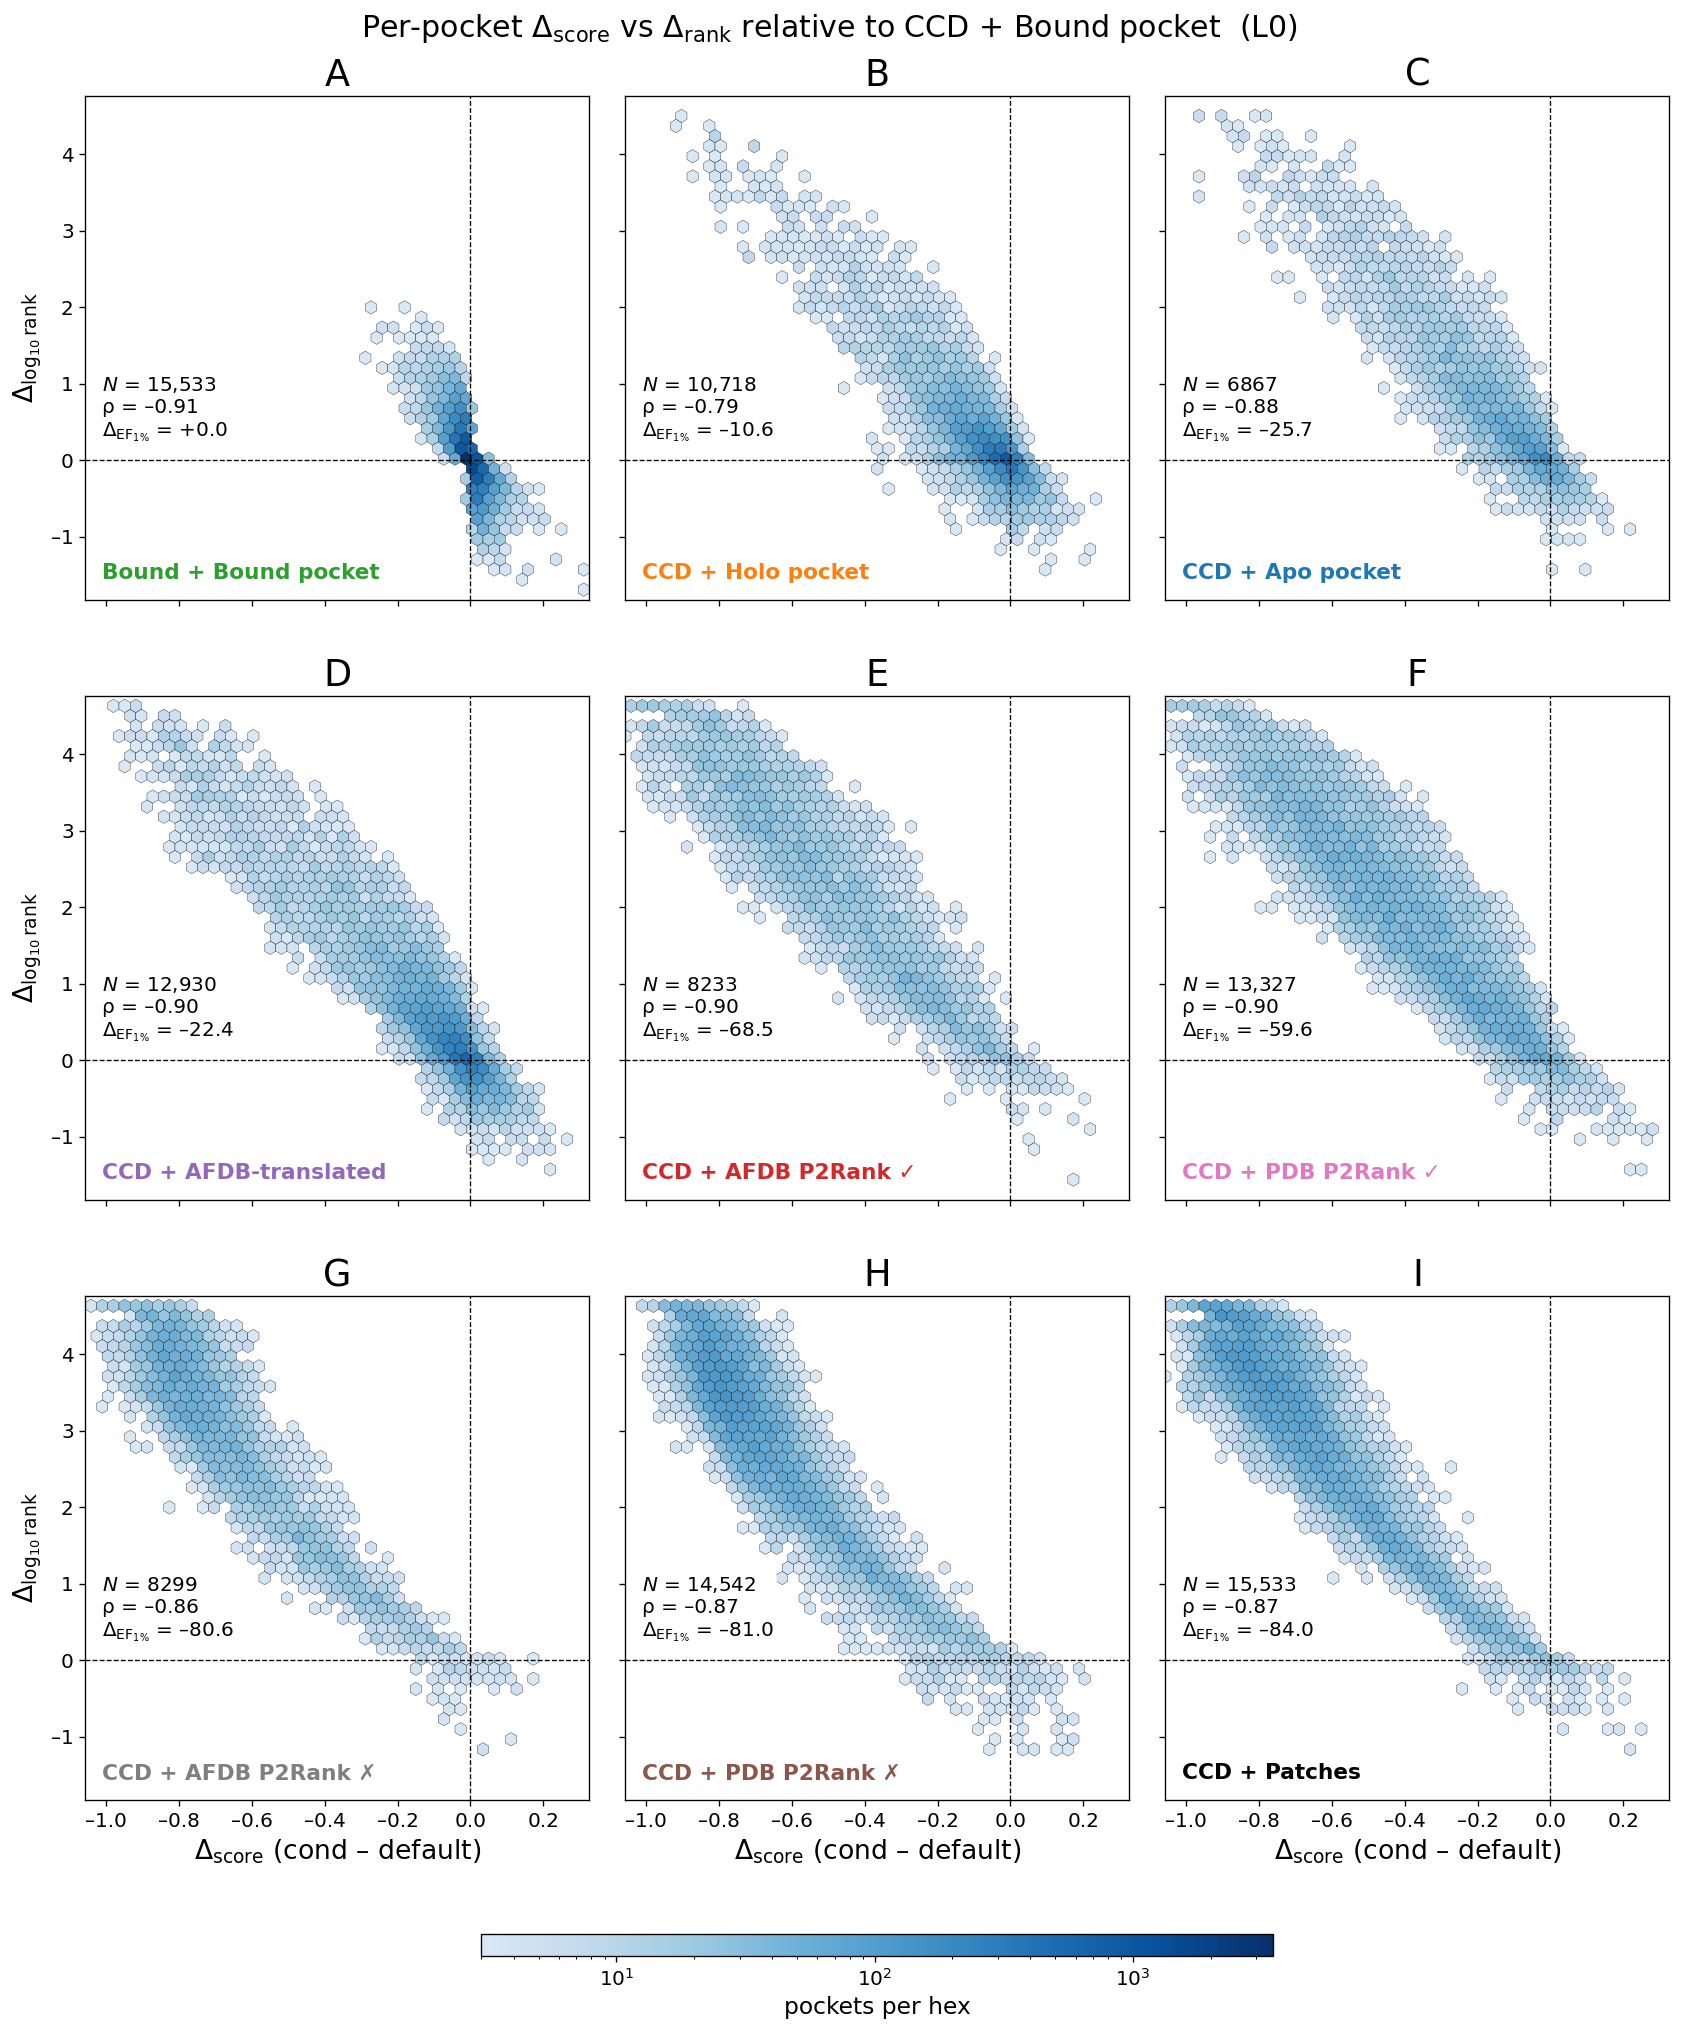

In [6]:
hex_panels('L0', gridsize=45, mincnt=3, fname='fig55_dscore_drank_hex_count_L0.png', colour_by='count')

### Same, at nb52's single-plot level (`L3<25`) — much thinner, coarser bins

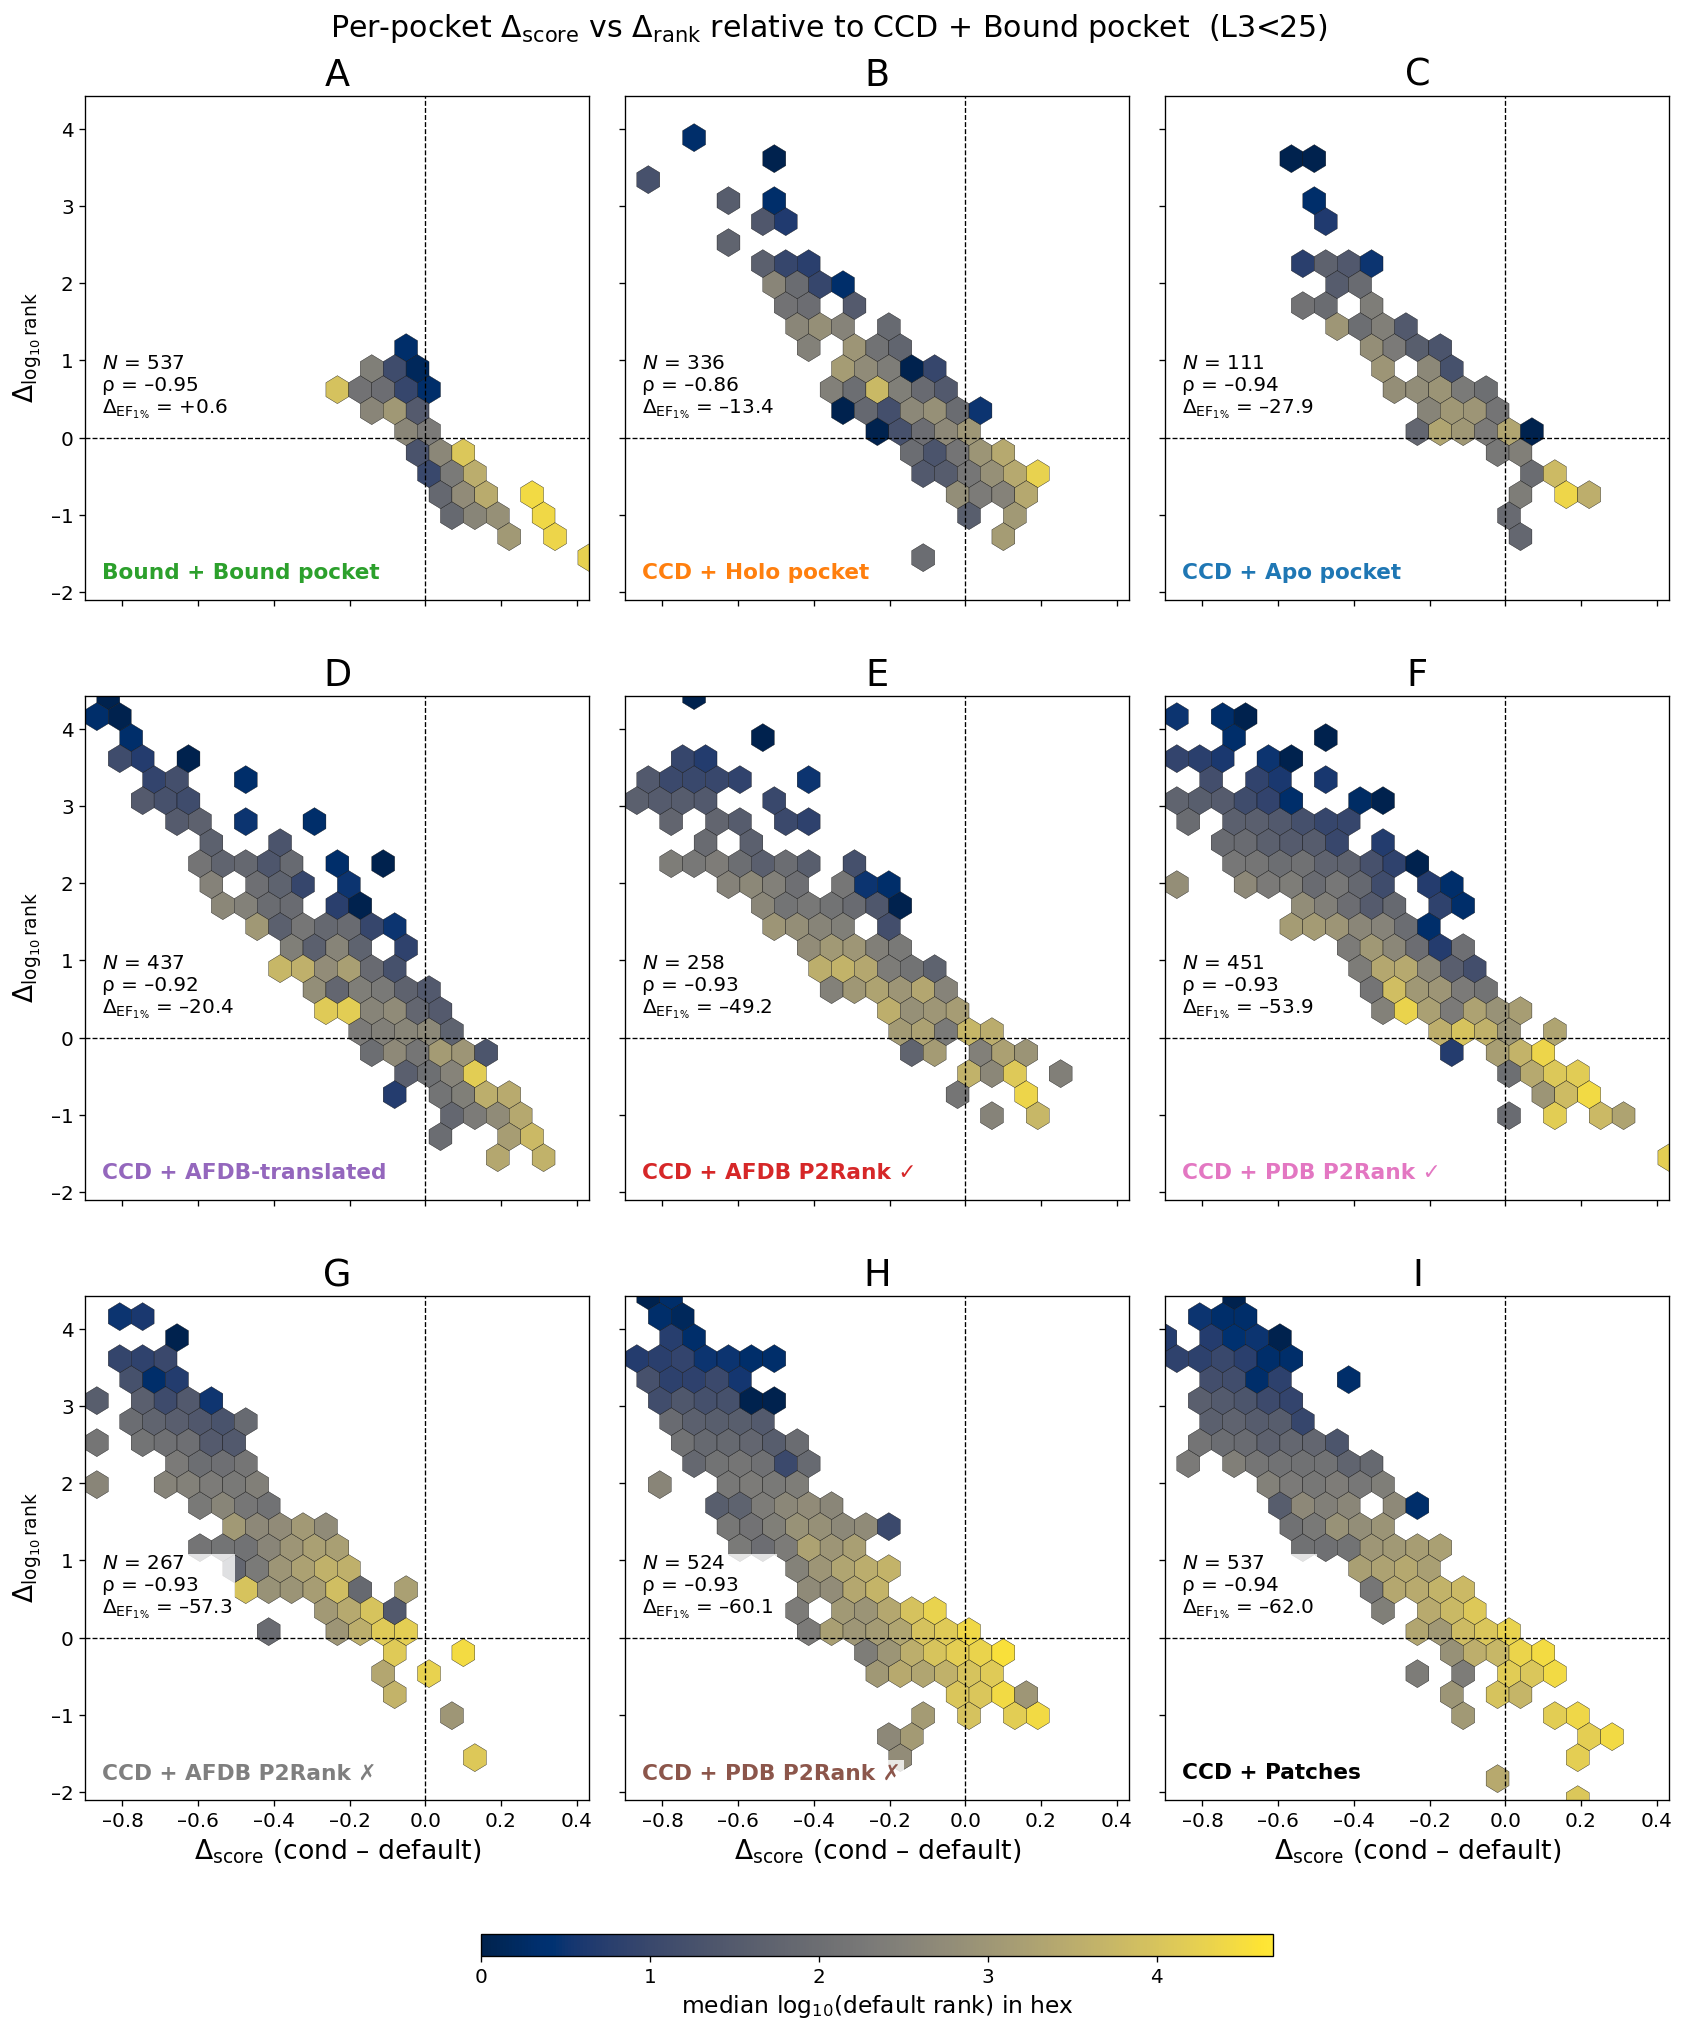

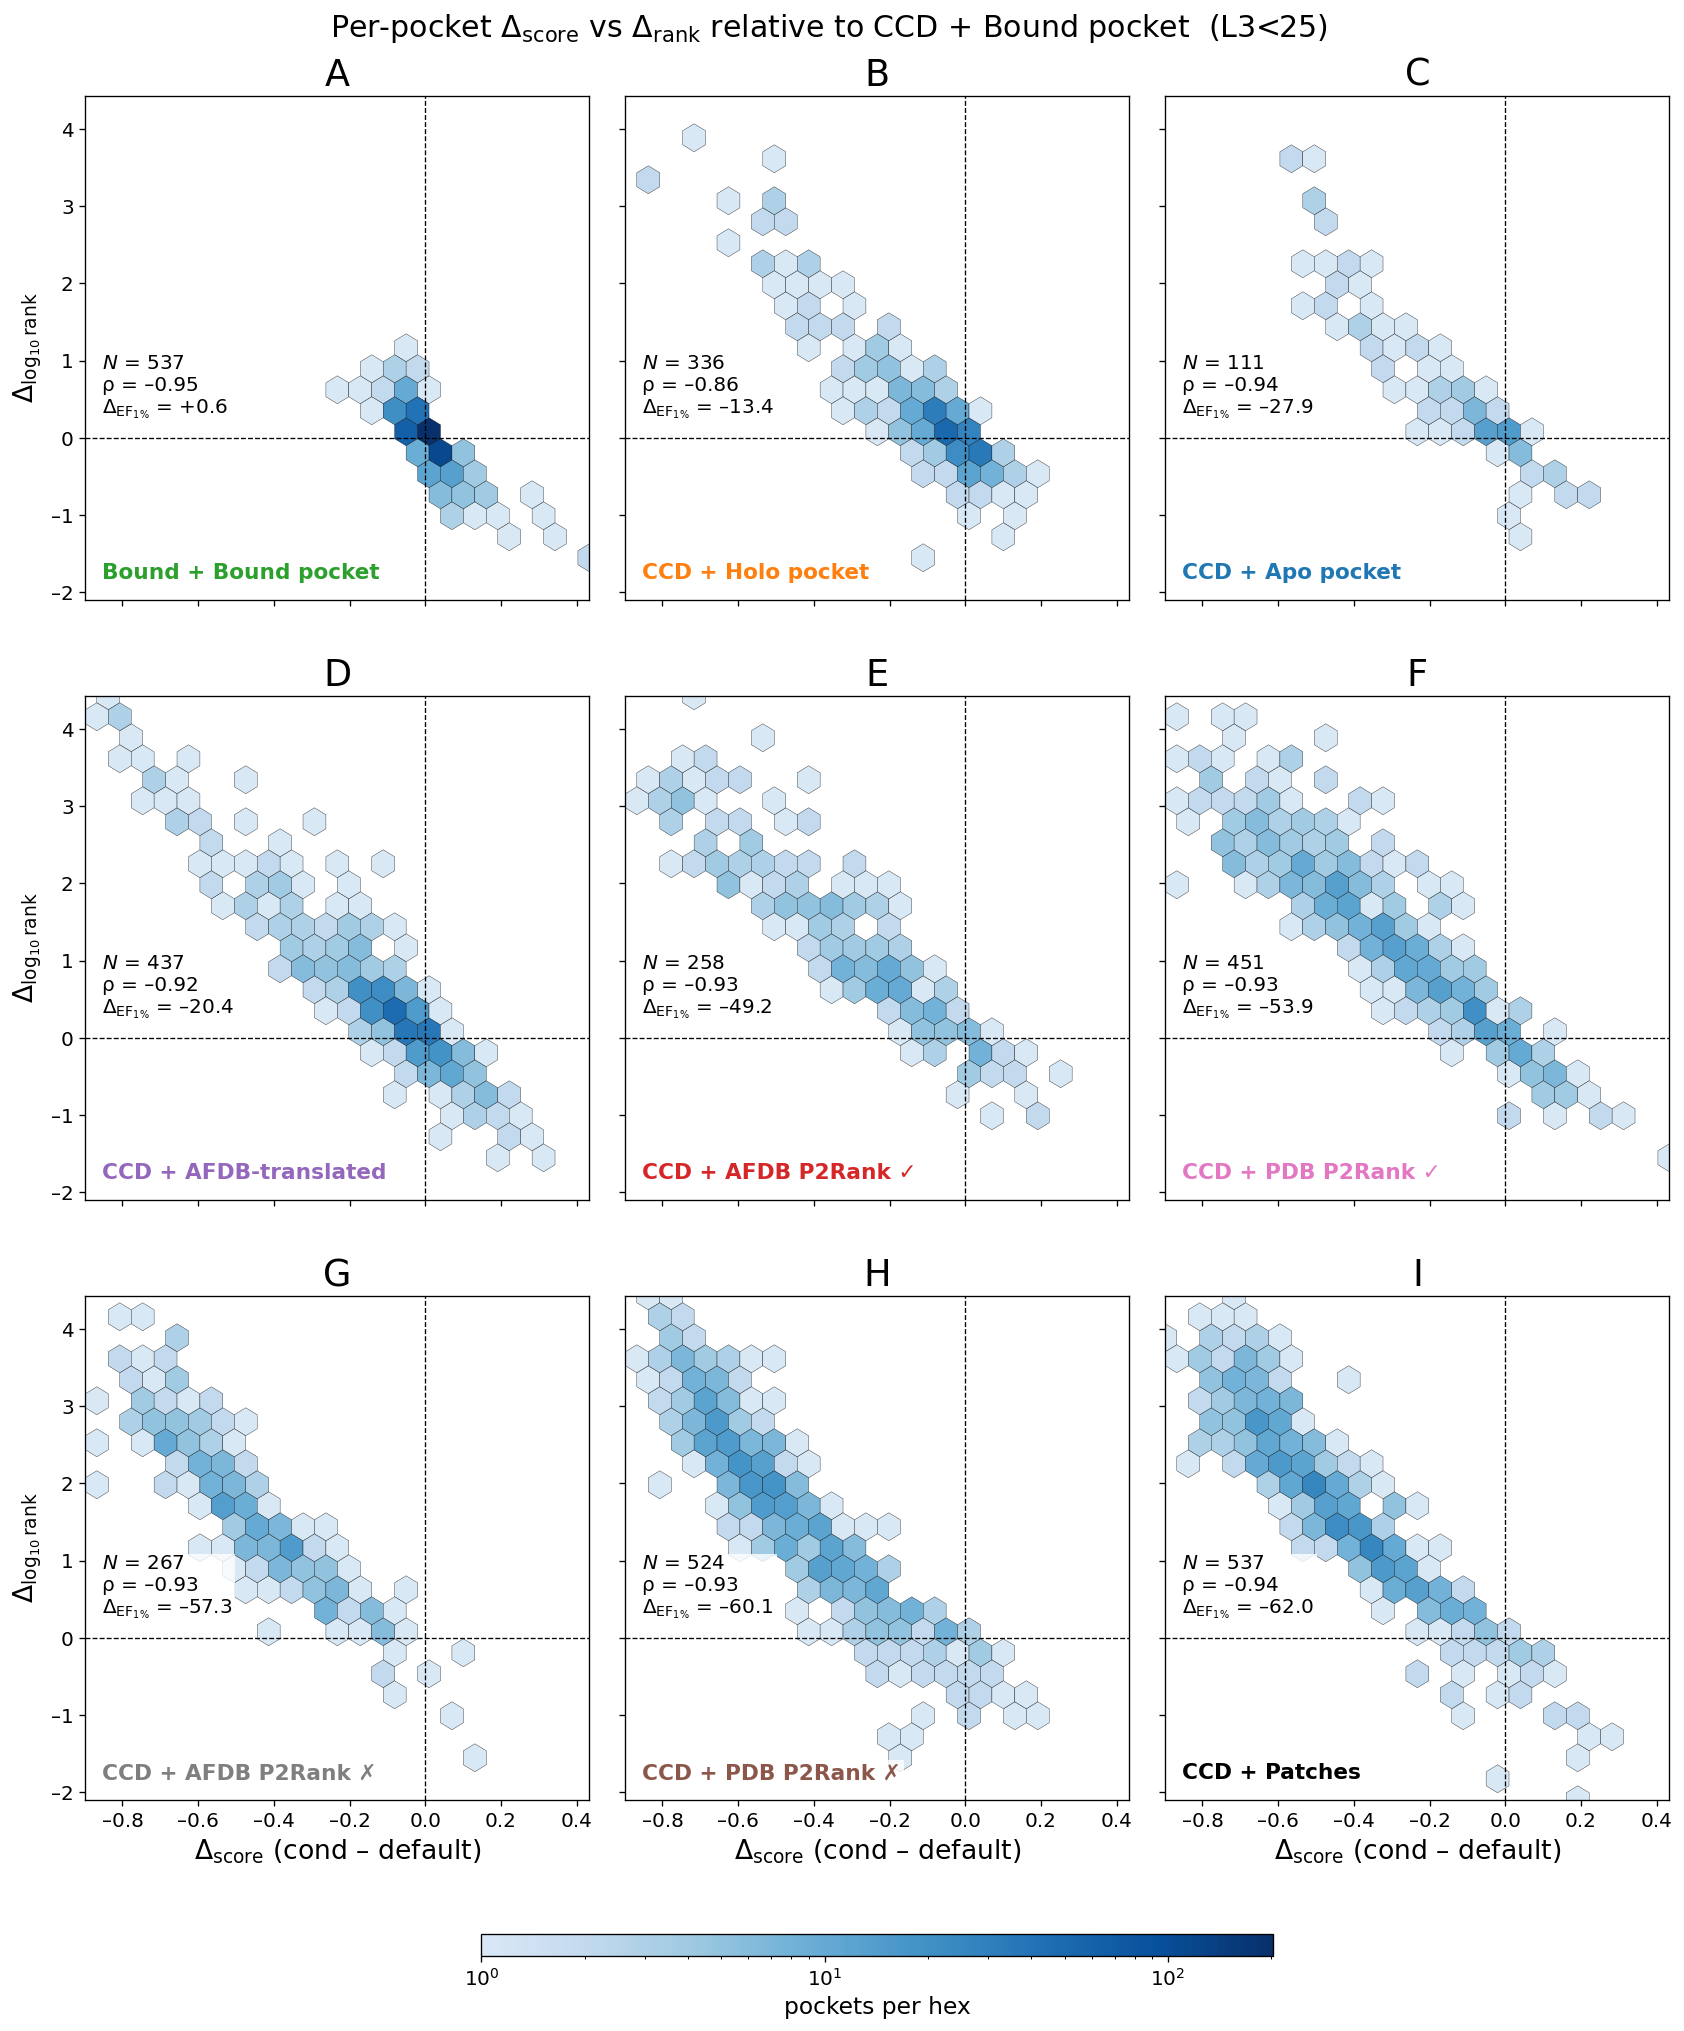

In [7]:
hex_panels(PLOT_LEVEL, gridsize=22, mincnt=1, fname='fig55_dscore_drank_hex_L3lt25.png')
hex_panels(PLOT_LEVEL, gridsize=22, mincnt=1, fname='fig55_dscore_drank_hex_count_L3lt25.png',
           colour_by='count')

## Plot 2 — Bridge: local ΔEF@1% and hit-loss rate as a function of Δscore

Pockets pooled per condition and binned on Δscore (fixed 0.05-wide bins, shared across conditions; bins with < 30 pockets dropped). In each bin:

* **left** — matched ΔEF@1% = EF(cond) – EF(default) on exactly the pockets in that bin;
* **right** — `P(miss in cond | hit in default)`, the mechanism by which EF is lost.

The thick grey line pools all non-default conditions. If coloured lines sit on the grey one, Δscore alone predicts EF loss regardless of *why* the pocket changed.

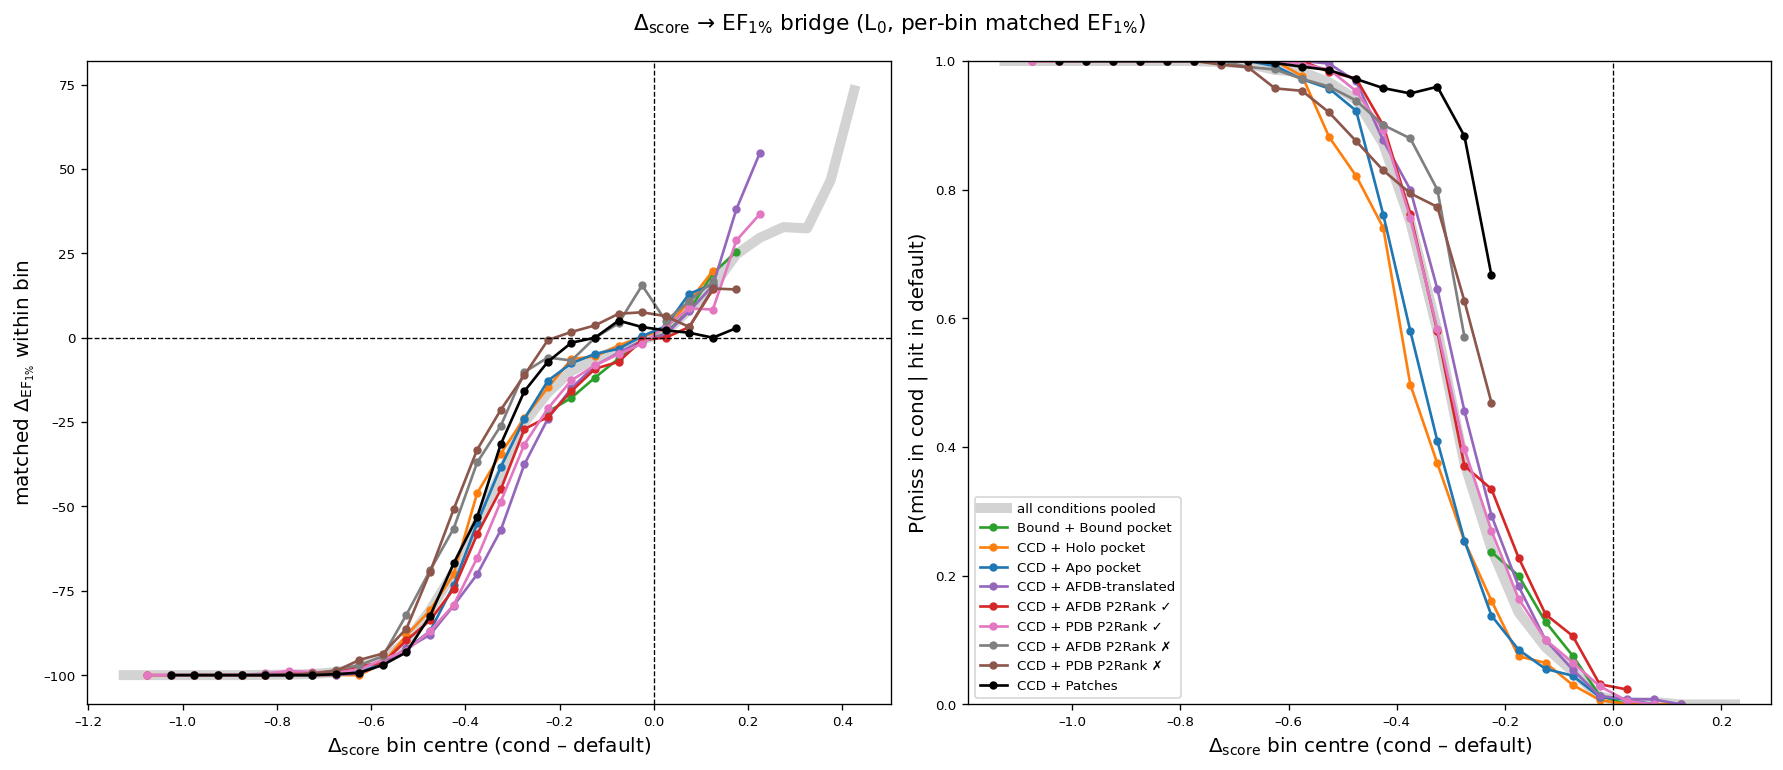

In [8]:
BIN_W, MIN_BIN_N = 0.05, 30
PAIRS_L0 = {c: paired(c, 'L0') for c in CMP_CONDS}
all_ds = np.concatenate([p['d_score'] for p in PAIRS_L0.values()])
edges = np.arange(np.floor(all_ds.min() / BIN_W) * BIN_W,
                  np.ceil(all_ds.max() / BIN_W) * BIN_W + BIN_W / 2, BIN_W)
centres = 0.5 * (edges[:-1] + edges[1:])


def binned(m: pd.DataFrame) -> pd.DataFrame:
    b = pd.cut(m['d_score'], edges, labels=centres)
    g = m.groupby(b, observed=True)
    out = pd.DataFrame({
        'n': g.size(),
        'ΔEF': g.apply(lambda s: ef(s['hit_cond']) - ef(s['hit_def'])),
        'n_def_hit': g['hit_def'].sum(),
        'p_loss': g.apply(lambda s: (s['hit_def'] & ~s['hit_cond']).sum()
                          / s['hit_def'].sum() if s['hit_def'].sum() else np.nan),
    })
    out.index = out.index.astype(float)
    return out


fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 6.5))
pool = binned(pd.concat(PAIRS_L0.values(), ignore_index=True))
pool = pool[pool['n'] >= MIN_BIN_N]
axL.plot(pool.index, pool['ΔEF'], color='lightgrey', lw=6, zorder=0, label='all conditions pooled')
pl = pool[pool['n_def_hit'] >= MIN_BIN_N]
axR.plot(pl.index, pl['p_loss'], color='lightgrey', lw=6, zorder=0)
bridge = {}
for cond in CMP_CONDS:
    b = binned(PAIRS_L0[cond]); bridge[cond] = b
    bl = b[b['n'] >= MIN_BIN_N]
    axL.plot(bl.index, bl['ΔEF'], marker='o', ms=4, lw=1.6,
             color=COND_COLOUR[cond], label=COND_LABEL[cond])
    br = b[b['n_def_hit'] >= MIN_BIN_N]
    axR.plot(br.index, br['p_loss'], marker='o', ms=4, lw=1.6, color=COND_COLOUR[cond])
for ax in (axL, axR):
    ax.axvline(0, color='black', lw=0.8, ls='--')
    ax.set_xlabel(r'$\Delta_{\mathrm{score}}$ bin centre (cond – default)')
axL.axhline(0, color='black', lw=0.8, ls='--')
axL.set_ylabel(r'matched $\Delta_{\mathrm{EF}_{1\%}}$ within bin')
axR.set_ylabel('P(miss in cond | hit in default)'); axR.set_ylim(0, 1)
axR.legend(*axL.get_legend_handles_labels(), fontsize=8, loc='lower left')
fig.suptitle(r'$\Delta_{\mathrm{score}}$ → EF$_{1\%}$ bridge (L$_0$, per-bin matched EF$_{1\%}$)', fontsize=13)
fig.tight_layout()
dash_ticks(fig)
fig.savefig(BENCH / 'fig55_dscore_ef_bridge_L0.png', dpi=600, bbox_inches='tight')
plt.show()

### Does Δscore explain the hit losses, or does the condition matter beyond Δscore?

Quantitative version of the "do the curves collapse?" question: a logistic model of `lost hit` (among default hits) on Δscore alone vs Δscore + condition dummies. A sizeable gain in log-likelihood from the condition terms means two conditions with the same Δscore lose hits at different rates — i.e. the background (other 49k molecules) moves differently between conditions, not just the true ligand's score.

In [9]:
import statsmodels.formula.api as smf

lm = pd.concat([p.assign(cond=c) for c, p in PAIRS_L0.items()], ignore_index=True)
lm = lm[lm['hit_def']].copy()
lm['lost'] = (~lm['hit_cond']).astype(int)
m0 = smf.logit('lost ~ d_score + I(d_score**2)', lm).fit(disp=0)
m1 = smf.logit('lost ~ d_score + I(d_score**2) + C(cond)', lm).fit(disp=0)
m2 = smf.logit('lost ~ (d_score + I(d_score**2)) * C(cond)', lm).fit(disp=0)
print(f'n default hits pooled over conditions: {len(lm):,}')
for name, mod in [('Δscore only', m0), ('+ condition offset', m1), ('+ condition × Δscore', m2)]:
    print(f'{name:24s} logLik={mod.llf:10.1f}  McFadden R²={mod.prsquared:.3f}  AIC={mod.aic:10.1f}')

n default hits pooled over conditions: 90,056
Δscore only              logLik=  -13358.5  McFadden R²=0.782  AIC=   26723.0
+ condition offset       logLik=  -12914.6  McFadden R²=0.790  AIC=   25851.1
+ condition × Δscore     logLik=  -12721.0  McFadden R²=0.793  AIC=   25495.9


## Plot 3 — Condition-level trajectories across the de-leak ladder

Each condition is one line through the nb52 ladder levels (`L0` = large marker). x = median Δscore of its paired pockets at that level, y = matched ΔEF@1%. Levels with < 30 paired pockets are dropped; the line goes dashed after the last level with ≥ 100 (same convention as nb52 plot 1).

Right panel: matched ΔEF@1% vs level directly.

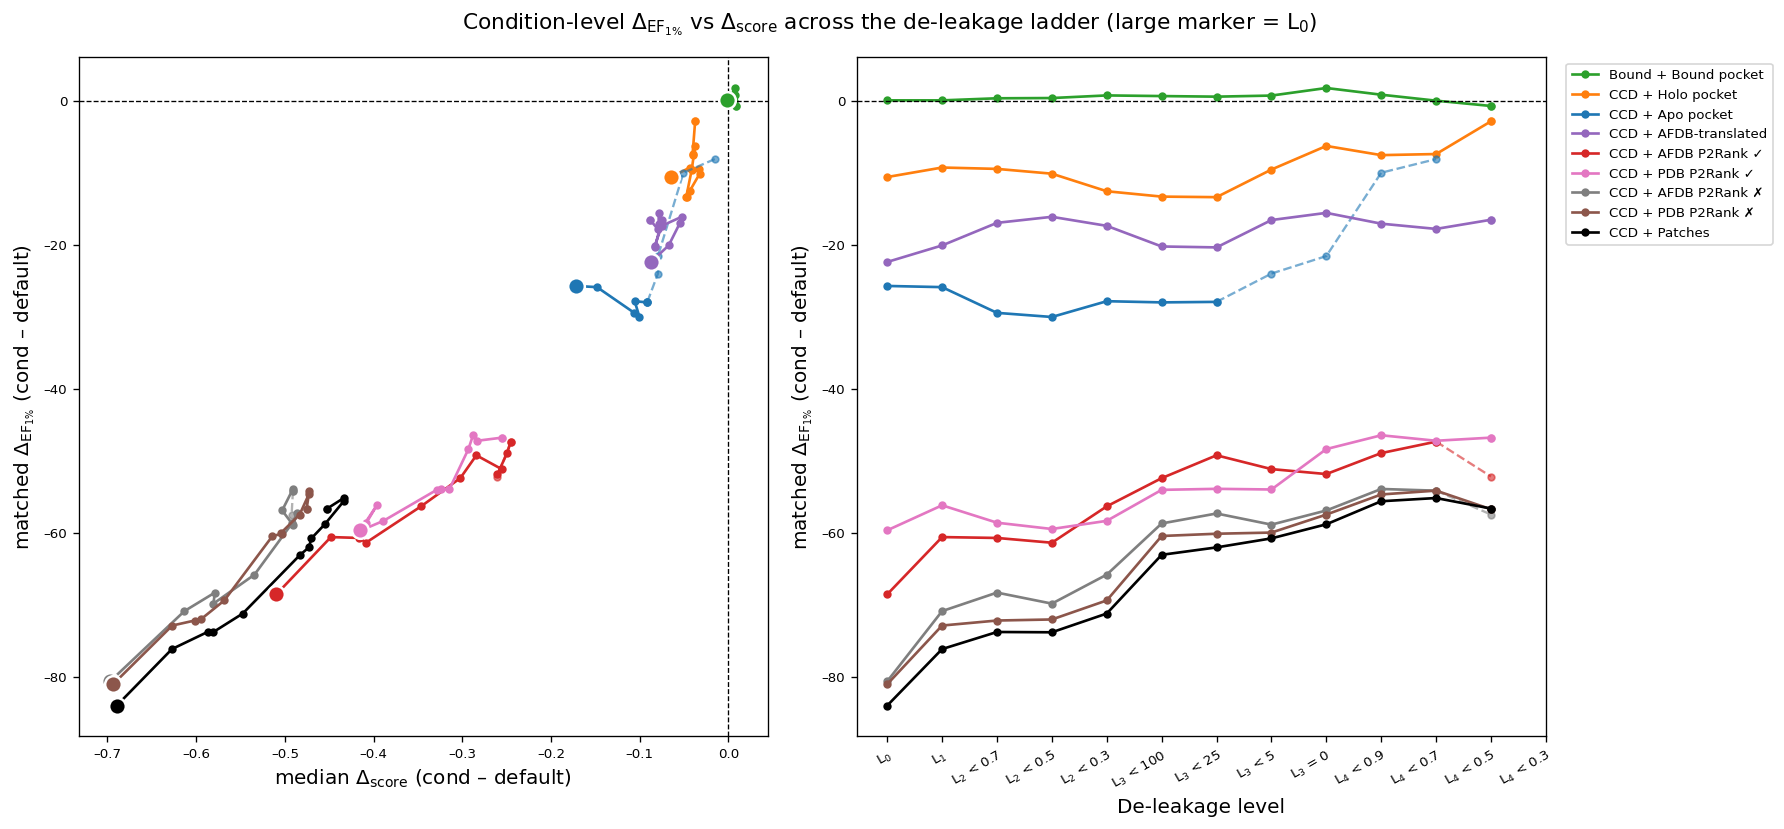

level,L0,L1,L2<0.7,L2<0.5,L2<0.3,L3<100,L3<25,L3<5,L3=0,L4<0.9,L4<0.7,L4<0.5,L4<0.3
condition,,,,,,,,,,,,,
Bound + Bound pocket,0.0,0.0,0.3,0.4,0.7,0.6,0.6,0.7,1.8,0.8,0.0,-0.7,NaN
CCD + Holo pocket,-10.6,-9.3,-9.5,-10.1,-12.6,-13.3,-13.4,-9.6,-6.3,-7.6,-7.4,-2.9,NaN
CCD + Apo pocket,-25.7,-25.9,-29.5,-30.0,-27.8,-28.0,-27.9,-24.0,-21.6,-10.0,-8.1,NaN,NaN
CCD + AFDB-translated,-22.4,-20.1,-17.0,-16.1,-17.4,-20.2,-20.4,-16.6,-15.6,-17.1,-17.8,-16.5,NaN
CCD + AFDB P2Rank ✓,-68.5,-60.6,-60.7,-61.4,-56.3,-52.4,-49.2,-51.1,-51.8,-48.9,-47.3,-52.2,NaN
CCD + PDB P2Rank ✓,-59.6,-56.2,-58.6,-59.5,-58.3,-54.0,-53.9,-54.0,-48.4,-46.4,-47.2,-46.8,NaN
CCD + AFDB P2Rank ✗,-80.6,-70.9,-68.3,-69.8,-65.8,-58.7,-57.3,-58.8,-56.9,-53.9,-54.1,-57.4,NaN
CCD + PDB P2Rank ✗,-81.0,-72.9,-72.2,-72.0,-69.4,-60.4,-60.1,-60.0,-57.5,-54.7,-54.1,-56.7,NaN
CCD + Patches,-84.0,-76.1,-73.8,-73.8,-71.2,-63.0,-62.0,-60.8,-58.8,-55.6,-55.2,-56.6,NaN


In [10]:
MIN_N, MIN_RELIABLE_N = 30, 100
traj_rows = []
for cond in CMP_CONDS:
    for lv in DE_LEVELS:
        m = paired(cond, lv)
        if len(m) < MIN_N:
            continue
        traj_rows.append({'condition': cond, 'level': lv, 'n': len(m),
                          'median Δscore': m['d_score'].median(),
                          'ΔEF': ef(m['hit_cond']) - ef(m['hit_def']),
                          'EF default (matched)': ef(m['hit_def'])})
traj = pd.DataFrame(traj_rows)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 7))
x_lv = {lv: i for i, lv in enumerate(DE_LEVELS)}
for cond in CMP_CONDS:
    t = traj[traj['condition'] == cond].reset_index(drop=True)
    if t.empty:
        continue
    col = COND_COLOUR[cond]
    rel = np.where(t['n'] >= MIN_RELIABLE_N)[0]
    k = rel.max() if len(rel) else 0
    for ax, xcol in [(axL, t['median Δscore']), (axR, t['level'].map(x_lv))]:
        ax.plot(xcol[:k + 1], t['ΔEF'][:k + 1], marker='o', ms=4, lw=1.6, color=col,
                label=COND_LABEL[cond] if ax is axR else None)
        ax.plot(xcol[k:], t['ΔEF'][k:], marker='o', ms=4, lw=1.4, ls='--', color=col, alpha=0.6)
    axL.plot(t['median Δscore'].iloc[0], t['ΔEF'].iloc[0], marker='o', ms=10,
             mec='white', mew=1.5, color=col, zorder=5)
for ax in (axL, axR):
    ax.axhline(0, color='black', lw=0.8, ls='--')
    ax.set_ylabel(r'matched $\Delta_{\mathrm{EF}_{1\%}}$ (cond – default)')
axL.axvline(0, color='black', lw=0.8, ls='--')
axL.set_xlabel(r'median $\Delta_{\mathrm{score}}$ (cond – default)')
axR.set_xticks(range(len(DE_LEVELS)))
axR.set_xticklabels(DE_LEVELS_FMT, rotation=30, ha='right', rotation_mode='anchor')
axR.set_xlabel('De-leakage level')
axR.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
fig.suptitle(r'Condition-level $\Delta_{\mathrm{EF}_{1\%}}$ vs $\Delta_{\mathrm{score}}$ across the de-leakage ladder (large marker = L$_0$)',
             fontsize=13)
fig.tight_layout()
dash_ticks(fig)
fig.savefig(BENCH / 'fig55_dEF_trajectories.png', dpi=600, bbox_inches='tight')
plt.show()

display(traj.pivot(index='condition', columns='level', values='ΔEF')
        .reindex(CMP_CONDS).reindex(columns=DE_LEVELS).round(1).rename(index=COND_LABEL))

---
## Notes

* **Files written to `RESULTS/benchmark/`:** `fig55_dscore_drank_hex_L0.png`, `fig55_dscore_drank_hex_L3lt25.png`, `fig55_dscore_drank_hex_count_L0.png`, `fig55_dscore_drank_hex_count_L3lt25.png`, `fig55_dscore_ef_bridge_L0.png`, `fig55_dEF_trajectories.png`. No new caches — everything comes from the nb43/nb52 per-pocket parquets.
* `DEFAULT` is a knob: set it to e.g. `'holo_ccd'` to re-centre every comparison on the holo pocket.
* Ties: `gt_rank = (# background molecules scoring strictly higher) + 1`, so ties favour the true ligand identically in both conditions.